# 🎯 Week 7 - Part 1: Feature Selection & Variance Visualization
### Data Science & Visualization · Team 1 · 24ADI204
**Objective:** Evaluate which engineered features carry the most predictive signal, filter low-variance columns, and inspect multicollinearity via correlation heatmaps.
---
**Interconnection Pipeline Step:** `3 of 4`  
- **Input:** `scaled_transformed_transactions.csv` (from Notebook 2: Scaling & Transformation)  
- **Output:** `selected_features_data.csv` (saved for Notebook 4: PCA & Variance Visualization)


In [1]:
# 1. Setup & Environment Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, mutual_info_classif

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
print('Libraries imported!')


Libraries imported!


In [2]:
# 2. Loading Interconnected Dataset from Notebook 2
input_file = 'scaled_transformed_transactions.csv'
if not os.path.exists(input_file):
    raise FileNotFoundError(f'{input_file} not found! Please run Notebook 2 first.')

df = pd.read_csv(input_file)
print(f'Loaded {len(df):,} scaled records from Notebook 2.')
X = df.drop(columns=['is_fraud'])
y = df['is_fraud']
print(f'Features: {X.columns.tolist()} (Shape: {X.shape})')


Loaded 100,000 scaled records from Notebook 2.
Features: ['log_amt', 'log_city_pop', 'customer_age', 'transaction_hour', 'distance_km', 'category_code', 'gender_encoded', 'is_night', 'state_freq'] (Shape: (100000, 9))


## Step 1: Variance Thresholding
**VarianceThreshold** removes features whose variance falls below a threshold (e.g. constant or near-constant features carrying almost no information).


In [3]:
# Calculate variance across all features
feature_variances = X.var().sort_values(ascending=False)
print('Feature Variances:')
print(feature_variances)


Feature Variances:
transaction_hour    1.000010
log_city_pop        1.000010
customer_age        1.000010
distance_km         1.000010
log_amt             1.000010
category_code       1.000010
gender_encoded      0.247849
is_night            0.180543
state_freq          0.000392
dtype: float64


<string>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


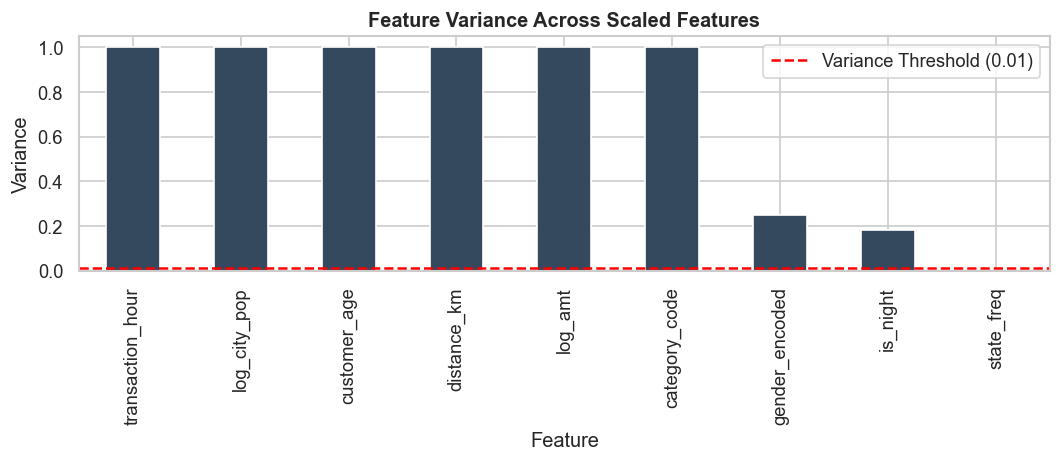

In [4]:
# Visualizing Feature Variances
plt.figure(figsize=(9, 4))
feature_variances.plot(kind='bar', color='#34495e')
plt.title('Feature Variance Across Scaled Features', fontweight='bold')
plt.xlabel('Feature')
plt.ylabel('Variance')
plt.axhline(y=0.01, color='red', linestyle='--', label='Variance Threshold (0.01)')
plt.legend()
plt.tight_layout()
plt.show()


## Step 2: Statistical Feature Selection (ANOVA F-Statistic)
**ANOVA F-test (`f_classif`)** measures the linear relationship between each feature and the target label `is_fraud`.
Higher F-scores indicate features with significantly different means between legitimate and fraudulent transactions.


In [5]:
f_selector = SelectKBest(score_func=f_classif, k='all')
f_selector.fit(X, y)
f_scores = pd.Series(f_selector.scores_, index=X.columns).sort_values(ascending=False)

print('ANOVA F-Scores (Ranking):')
print(f_scores)


ANOVA F-Scores (Ranking):
log_amt             2420.877986
is_night            2019.773851
category_code         72.734962
transaction_hour      19.943354
customer_age          12.986341
state_freq            12.188211
gender_encoded         0.337433
distance_km            0.087444
log_city_pop           0.013873
dtype: float64


<string>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


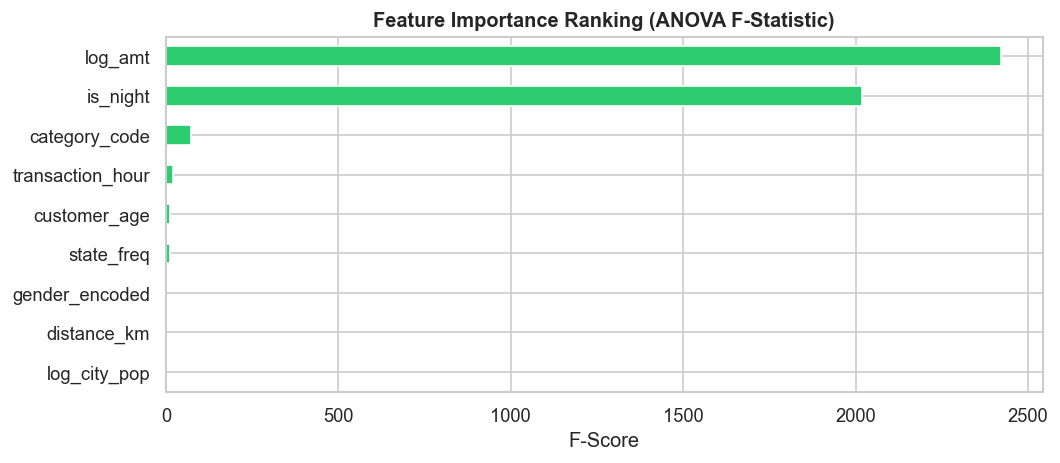

In [6]:
# Visualizing Feature Importance by F-Score
plt.figure(figsize=(9, 4))
f_scores.sort_values(ascending=True).plot(kind='barh', color='#2ecc71')
plt.title('Feature Importance Ranking (ANOVA F-Statistic)', fontweight='bold')
plt.xlabel('F-Score')
plt.tight_layout()
plt.show()


## Step 3: Correlation Matrix & Multicollinearity
We inspect pairwise Pearson correlation coefficients to verify that features are not redundantly duplicated.


<string>:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


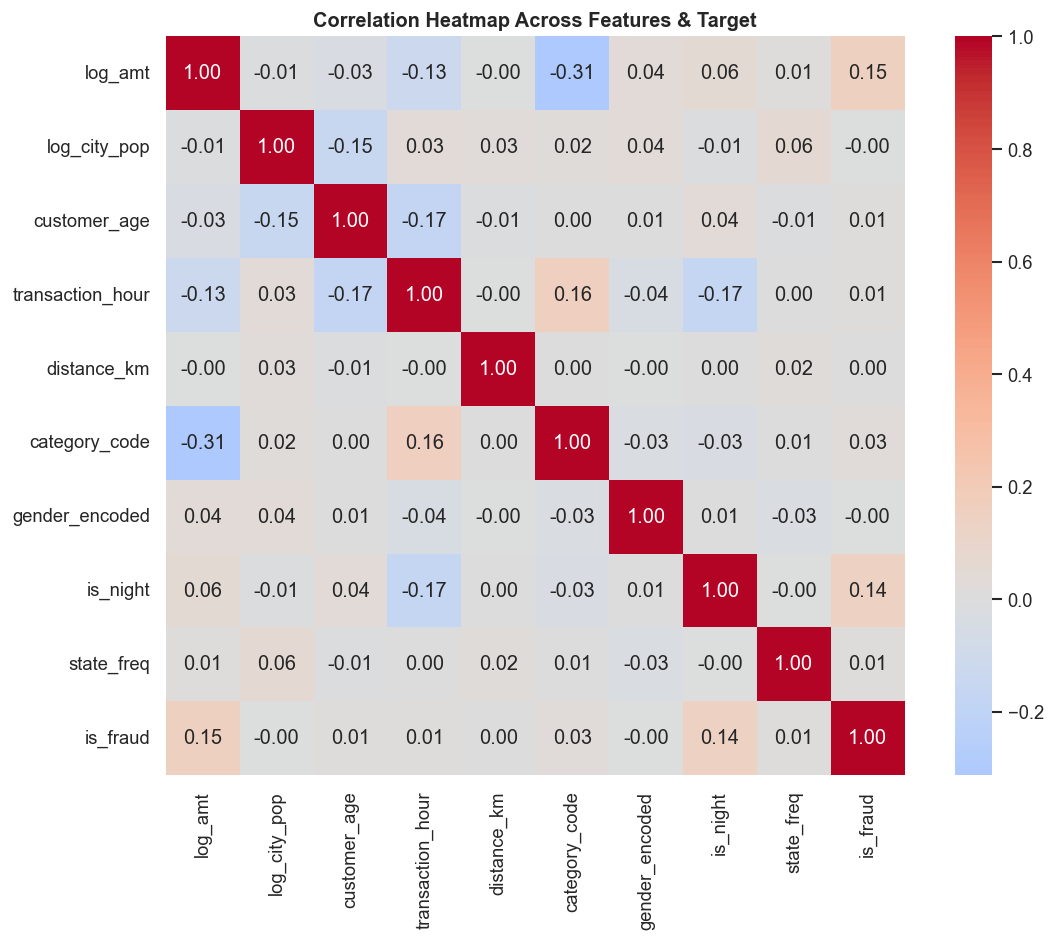

In [7]:
plt.figure(figsize=(10, 8))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar=True, square=True)
plt.title('Correlation Heatmap Across Features & Target', fontweight='bold')
plt.tight_layout()
plt.show()


## Step 4: Selecting Optimal Features & Saving for Notebook 4
Based on F-scores and correlation analysis, we select the top non-redundant predictive features.


In [8]:
# Select top predictive features
top_features = ['log_amt', 'is_night', 'category_code', 'customer_age', 'transaction_hour', 'log_city_pop', 'distance_km']
selected_df = df[top_features].copy()
selected_df['is_fraud'] = y.values

output_file = 'selected_features_data.csv'
selected_df.to_csv(output_file, index=False)
print(f'Successfully saved selected features to: {output_file} (Shape: {selected_df.shape})')


Successfully saved selected features to: selected_features_data.csv (Shape: (100000, 8))
